In [1]:
import numpy as np
from matplotlib import pyplot as plt

## iii) & iv)

The implementation uses the minimal form **$U(q) = \lambda * q => \frac{\partial U}{\partial q} = \lambda$** (function is 1-dimensional) , hyperparameter m = 1 => **$K(p) = \frac{p^2}{2}$**  , and constraint **$q >= 0$**

In [2]:
### HMC algorithm implementation
def hmc_exp(n):
    lamb = 2
    L = 25
    epsilon = 0.1
    q_t = 0.5
    samples = [0.5]
    
    for i in range(n):
        p_t = np.random.normal(0,1)
        q_start = q_t
        p_start = p_t
        
        # Leapfrog loop
        for l in range(L):
            p_t = p_t - (epsilon/2)*lamb
            q_t  = q_t + epsilon*p_t
            
            if q_t < 0:
                q_t = -q_t  # Turn position back to positive (Constraint q >= 0)
                p_t = -p_t
                
            p_t = p_t - (epsilon/2)*lamb
            
            
        p_accept = min(1, np.exp(-lamb*q_t + lamb*q_start - 0.5*p_t**2 + 0.5*p_start**2))
        rand = np.random.uniform(0,1)
        
        if rand > p_accept:
            q_t = q_start
            
        samples.append(q_t)
    
    return samples

Text(0.5, 1.0, 'HMC simulation')

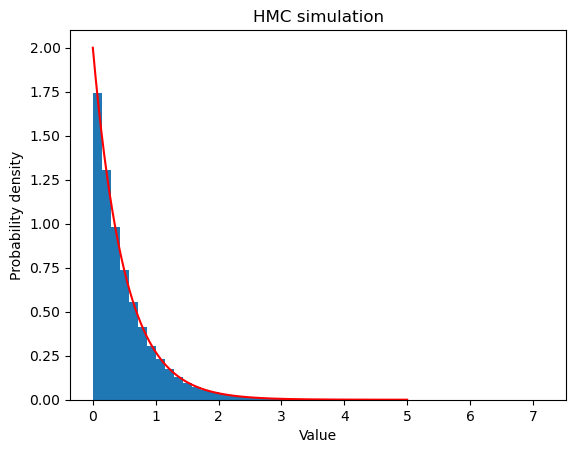

In [4]:
x = np.linspace(0, 5, 1000)
y = 2*np.exp(-2*x)
samples = hmc_exp(10**6)
plt.hist(samples, bins = 50, density=True)
plt.plot(x,y,color = 'r')
plt.xlabel("Value")
plt.ylabel("Probability density")
plt.title('HMC simulation')

## v) $\varepsilon$ used is 0.1